In [47]:
import torch
from transformers import Sam3Model, Sam3Processor, BitsAndBytesConfig
from huggingface_hub.utils import GatedRepoError

# Configure 4-bit quantization
quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True
)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f">>> Device: {device}")

# Load the processor and model with 4-bit config
try:
    print(">>> Checking model access and loading...")
    processor = Sam3Processor.from_pretrained("facebook/sam3")
    model = Sam3Model.from_pretrained(
        "facebook/sam3",
        quantization_config=quantization_config,
        device_map="auto"
    )
    print(">>> Success! You now have access and the model is loaded.")
except GatedRepoError:
    print(">>> Access pending: Your application has not been approved yet. Try again later.")
except Exception as e:
    print(f">>> An error occurred: {e}")

print(">>> Model successfully loaded in 4-bit mode!")

>>> Device: cuda
>>> Checking model access and loading...


Loading weights: 100%|██████████| 1468/1468 [00:07<00:00, 185.56it/s]

>>> Success! You now have access and the model is loaded.
>>> Model successfully loaded in 4-bit mode!


In [48]:
# Count parameters and model size
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f">>> Total Parameters: {total_params}")
print(f">>> Trainable Parameters: {trainable_params}")

param_size = sum(p.numel() * p.element_size() for p in model.parameters())
buffer_size = sum(b.numel() * b.element_size() for b in model.buffers())

total_size_mb = (param_size + buffer_size) / (1024 ** 3)
print(f">>> Model Size: {total_size_mb:.2f} GB")

>>> Total Parameters: 452989110
>>> Trainable Parameters: 65601846
>>> Model Size: 0.61 GB


In [49]:
from PIL import Image

# Load the grayscale image and convert it to RGB format
image_path = "images/zil_00-10-83-13-99_261012_112259_Z.png"
image = Image.open(image_path).convert("RGB")   # Converts single channel to 3-channel RGB

# Process the image and prompt
text_prompt = "circuit module"

inputs = processor(images=image, text=text_prompt, return_tensors="pt").to(model.device)

# Run inference
with torch.no_grad():
    outputs = model(**inputs)

# Post-process the results to get segmentation masks
results = processor.post_process_instance_segmentation(
    outputs,
    threshold=0.5,
    target_sizes=[image.size[::-1]]             # image.size returns (width, height), so [::-1] gives (height, width)
)

print("Segmentation complete! Found instances:", len(results[0]["masks"]))

Segmentation complete! Found instances: 1


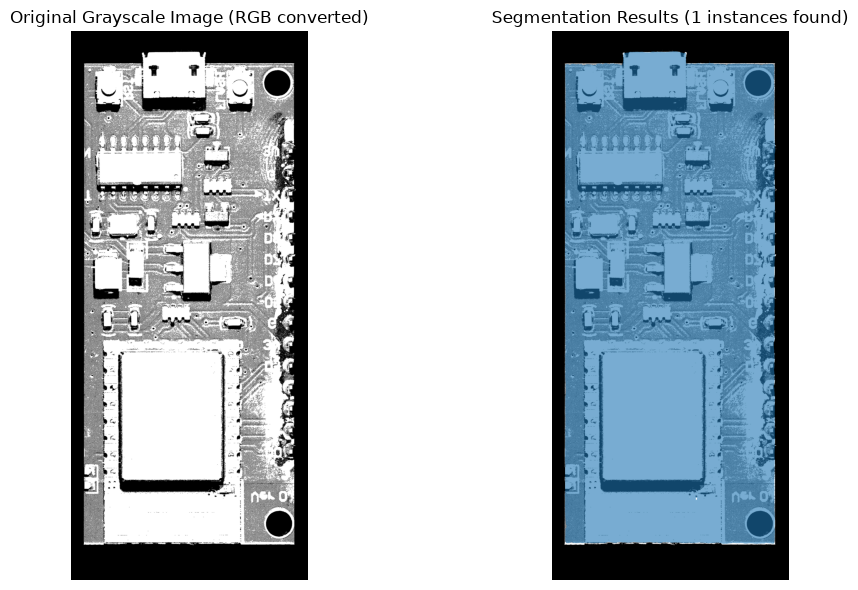

In [50]:
import matplotlib.pyplot as plt
import numpy as np

ALPHA = 0.6

# Bool masks on the GPU first: much less data to copy than float masks
masks = results[0]["masks"].bool().cpu().numpy()          # (N, H, W)
N, H, W = masks.shape

# Same colors as before (one per instance, including empty ones)
colors = plt.get_cmap("tab20")(np.linspace(0, 1, N))[:, :3].astype(np.float32)

# Blend all masks into ONE RGBA layer, in the same order as before.
# The rule "new = a*color + (1-a)*old" is what Matplotlib does when it stacks layers.
prem_rgb = np.zeros((H, W, 3), np.float32)   # color, pre-multiplied by alpha
acc_a    = np.zeros((H, W),    np.float32)   # alpha so far

for i in range(N):
    m = masks[i]
    if not m.any():
        continue
    prem_rgb[m] = ALPHA * colors[i] + (1 - ALPHA) * prem_rgb[m]
    acc_a[m]    = ALPHA + (1 - ALPHA) * acc_a[m]

overlay = np.zeros((H, W, 4), np.float32)
covered = acc_a > 0
overlay[covered, :3] = prem_rgb[covered] / acc_a[covered, None]
overlay[..., 3] = acc_a

# Plot
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(image)
axes[0].set_title("Original Grayscale Image (RGB converted)")
axes[0].axis("off")

axes[1].imshow(image)
axes[1].imshow(overlay)
axes[1].set_title(f"Segmentation Results ({N} instances found)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [51]:
from PIL import Image

# Load the grayscale image and convert it to RGB format
image_path = "images/zil_00-10-83-13-99_261012_112259_Z.png"
image = Image.open(image_path).convert("RGB")   # Converts single channel to 3-channel RGB

# Process the image and prompt
text_prompt = "electronic component"

inputs = processor(images=image, text=text_prompt, return_tensors="pt").to(model.device)

# Run inference
with torch.no_grad():
    outputs = model(**inputs)

# Post-process the results to get segmentation masks
results = processor.post_process_instance_segmentation(
    outputs,
    threshold=0.5,
    target_sizes=[image.size[::-1]]             # image.size returns (width, height), so [::-1] gives (height, width)
)

print("Segmentation complete! Found instances:", len(results[0]["masks"]))

Segmentation complete! Found instances: 25


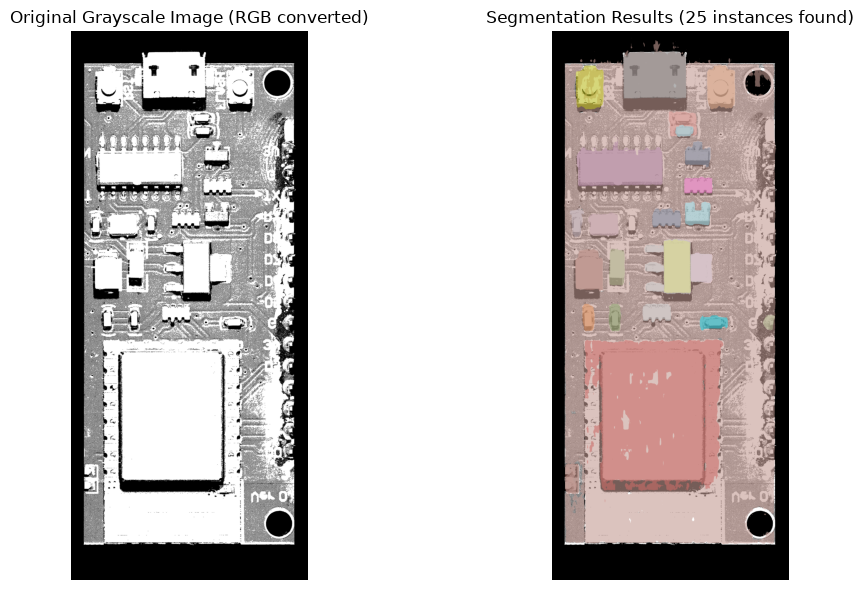

In [52]:
import matplotlib.pyplot as plt
import numpy as np

ALPHA = 0.6

# Bool masks on the GPU first: much less data to copy than float masks
masks = results[0]["masks"].bool().cpu().numpy()          # (N, H, W)
N, H, W = masks.shape

# Same colors as before (one per instance, including empty ones)
colors = plt.get_cmap("tab20")(np.linspace(0, 1, N))[:, :3].astype(np.float32)

# Blend all masks into ONE RGBA layer, in the same order as before.
# The rule "new = a*color + (1-a)*old" is what Matplotlib does when it stacks layers.
prem_rgb = np.zeros((H, W, 3), np.float32)   # color, pre-multiplied by alpha
acc_a    = np.zeros((H, W),    np.float32)   # alpha so far

for i in range(N):
    m = masks[i]
    if not m.any():
        continue
    prem_rgb[m] = ALPHA * colors[i] + (1 - ALPHA) * prem_rgb[m]
    acc_a[m]    = ALPHA + (1 - ALPHA) * acc_a[m]

overlay = np.zeros((H, W, 4), np.float32)
covered = acc_a > 0
overlay[covered, :3] = prem_rgb[covered] / acc_a[covered, None]
overlay[..., 3] = acc_a

# Plot
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(image)
axes[0].set_title("Original Grayscale Image (RGB converted)")
axes[0].axis("off")

axes[1].imshow(image)
axes[1].imshow(overlay)
axes[1].set_title(f"Segmentation Results ({N} instances found)")
axes[1].axis("off")

plt.tight_layout()
plt.show()